Business Problem:
A company wants to estimate an employee's salary based on their years of professional experience.
Build a Simple Linear Regression model that predicts an employee's salary based only on their years of experience.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv(r"Downloads/archive (7)/employee_performance.csv")

In [3]:
df.head()

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
0,E0524,49,Female,Operations,5.6,67.8,33013
1,E0603,55,Female,Sales,5.5,NaN,42640
2,E0527,29,Female,Sales,10.7,68.8,72180
3,E0032,30,Female,Operations,9.8,NaN,65750
4,E0617,58,Male,Sales,11.5,72.8,74830


In [4]:
df.tail()

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
1015,E0107,26,Male,IT,9.2,83.9,51410
1016,E0271,40,Female,Finance,4.8,77.4,48858
1017,E0861,47,Male,Operations,2.0,76.5,24647
1018,E0436,57,Male,HR,1.8,55.7,26744
1019,E0103,58,Male,IT,7.9,86.5,53764


In [5]:
df.shape

(1020, 7)

In [6]:
df.columns.tolist()

['Employee_ID',
 'Age',
 'Gender',
 'Department',
 'Experience_Years',
 'Performance_Score',
 'Salary']

In [7]:
df.dtypes

Employee_ID           object
Age                    int64
Gender                object
Department            object
Experience_Years     float64
Performance_Score    float64
Salary                 int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Employee_ID        1020 non-null   object 
 1   Age                1020 non-null   int64  
 2   Gender             1020 non-null   object 
 3   Department         1020 non-null   object 
 4   Experience_Years   988 non-null    float64
 5   Performance_Score  990 non-null    float64
 6   Salary             1020 non-null   int64  
dtypes: float64(2), int64(2), object(3)
memory usage: 55.9+ KB


In [9]:
df.describe()

,Age,Experience_Years,Performance_Score,Salary
count,1020.000000,988.000000,990.000000,1020.000000
mean,40.898039,7.209919,69.755657,52905.790196
std,11.160063,3.070575,9.935075,33016.717394
min,22.000000,0.000000,37.600000,5000.000000
25%,31.000000,5.200000,63.025000,38867.750000
50%,42.000000,7.250000,70.050000,50595.500000
75%,50.000000,9.200000,76.675000,60984.250000
max,59.000000,16.800000,97.500000,400000.000000


In [10]:
df.isnull().sum()

Employee_ID           0
Age                   0
Gender                0
Department            0
Experience_Years     32
Performance_Score    30
Salary                0
dtype: int64

In [11]:
df['Experience_Years'].fillna(df['Experience_Years'].median(),inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_21352\4283573778.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Experience_Years'].fillna(df['Experience_Years'].median(),inplace=True)


In [12]:
df['Performance_Score'].fillna(df['Performance_Score'].median(),inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_21352\1227082612.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Performance_Score'].fillna(df['Performance_Score'].median(),inplace=True)


In [13]:
df.isnull().sum()

Employee_ID          0
Age                  0
Gender               0
Department           0
Experience_Years     0
Performance_Score    0
Salary               0
dtype: int64

In [14]:
df.duplicated().sum()

20

In [15]:
df = df.drop_duplicates()

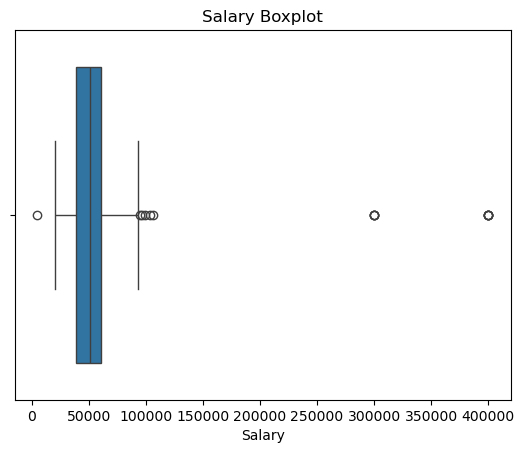

In [16]:
sns.boxplot(x=df['Salary'])
plt.title('Salary Boxplot')
plt.show()

In [17]:
df[df['Salary'] >= 200000][['Employee_ID', 'Age', 'Gender', 'Department','Experience_Years', 'Performance_Score', 'Salary']]

,Employee_ID,Age,Gender,Department,Experience_Years,Performance_Score,Salary
118,E0758,29,Female,HR,5.6,80.6,300000
386,E0165,53,Female,Marketing,9.5,76.9,300000
408,E0674,26,Female,HR,10.1,79.2,400000
463,E0224,41,Male,Sales,11.0,72.4,400000
492,E0418,34,Male,HR,6.0,71.5,400000
516,E0427,50,Male,IT,10.9,67.0,300000
519,E0976,45,Female,Marketing,11.9,56.3,300000
819,E0578,34,Male,Marketing,4.6,64.2,400000
898,E0493,30,Female,Marketing,8.1,71.5,400000


In [18]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 38980.0
Q3: 61079.25
IQR: 22099.25
Lower limit: 5831.125
Upper limit: 94228.125


In [19]:
df_clean = df[(df['Salary'] >= lower_limit) & (df['Salary'] <= upper_limit)].copy()

In [20]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1000, 7)
Cleaned shape: (985, 7)


In [21]:
df_clean['Experience_Years'] = df_clean['Experience_Years'].fillna(
    df_clean['Experience_Years'].median()
)

df_clean['Performance_Score'] = df_clean['Performance_Score'].fillna(
    df_clean['Performance_Score'].median()
)

In [22]:
print(df_clean.isnull().sum())

Employee_ID          0
Age                  0
Gender               0
Department           0
Experience_Years     0
Performance_Score    0
Salary               0
dtype: int64


In [23]:
df_clean = df_clean.drop_duplicates()

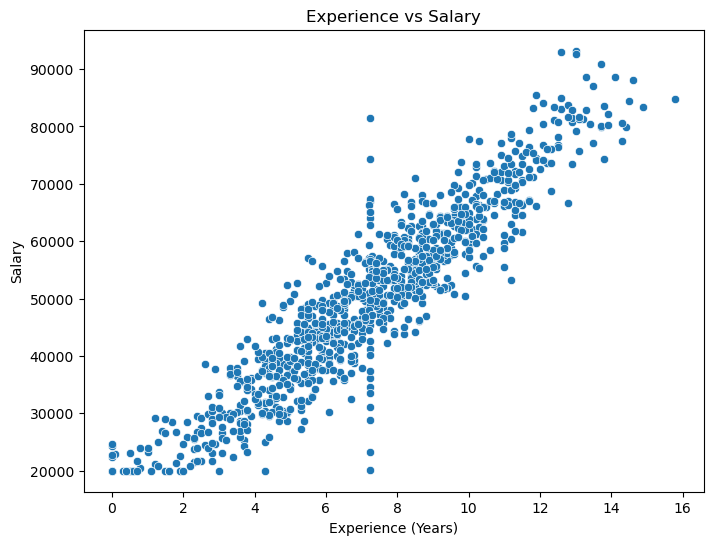

In [24]:
plt.figure(figsize=(8,6))
sns.scatterplot(data=df_clean,x='Experience_Years',y='Salary')
plt.title('Experience vs Salary')
plt.xlabel('Experience (Years)')
plt.ylabel('Salary')
plt.show()

In [25]:
df_clean[['Experience_Years', 'Salary']].corr()

,Experience_Years,Salary
Experience_Years,1.000000,0.927505
Salary,0.927505,1.000000


In [26]:
X = df_clean[['Experience_Years']]

y = df_clean['Salary']

In [27]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (985, 1)
y shape: (985,)


In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [31]:
print(X_train.shape)
print(X_test.shape)

(788, 1)
(197, 1)


In [32]:
model = LinearRegression()
model.fit(X_train, y_train)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

In [33]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 15474.299912325827
Coefficient: 4866.935656177324


In [34]:
train_r2 = r2_score(y_train, train_predictions)

test_r2 = r2_score(y_test, test_predictions)

print("Train R2:", train_r2)
print("Test R2:", test_r2)

Train R2: 0.8646632627564277
Test R2: 0.8398187240365415


In [35]:
mae = mean_absolute_error(y_test,test_predictions)
print("Test MAE:", mae)

Test MAE: 4804.267716085912


In [36]:
mse = mean_squared_error(y_test,test_predictions)
print("Test MSE:", mse)

Test MSE: 38007175.899225


In [37]:
rmse = np.sqrt(mse)
print("Test RMSE:", rmse)

Test RMSE: 6164.996017778519


In [38]:
comparison = pd.DataFrame({'Actual Salary': y_test.values,'Predicted Salary': test_predictions})
comparison.head(10)

,Actual Salary,Predicted Salary
0,56904,60250.107949
1,58175,48569.462374
2,21727,29101.719750
3,49147,35915.429668
4,83455,87991.641189
5,46661,52463.010899
6,49287,51976.317334
7,51628,60736.801515
8,37142,46622.688112
9,58842,59763.414384


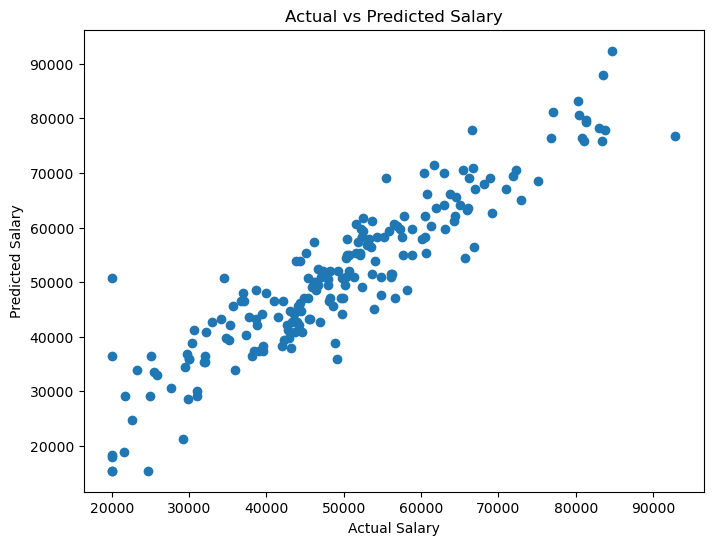

In [39]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, test_predictions)
plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Actual vs Predicted Salary')
plt.show()

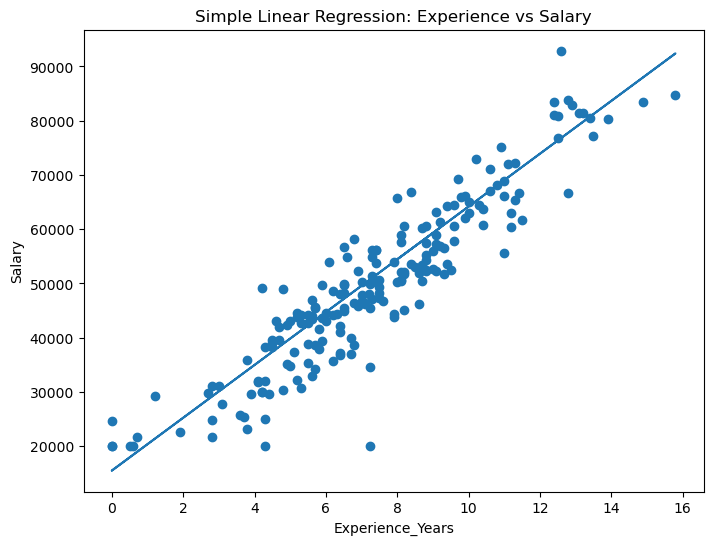

In [40]:
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test)
plt.plot(X_test,test_predictions)
plt.xlabel('Experience_Years')
plt.ylabel('Salary')
plt.title('Simple Linear Regression: Experience vs Salary')
plt.show()

In [41]:
residuals = y_test - test_predictions

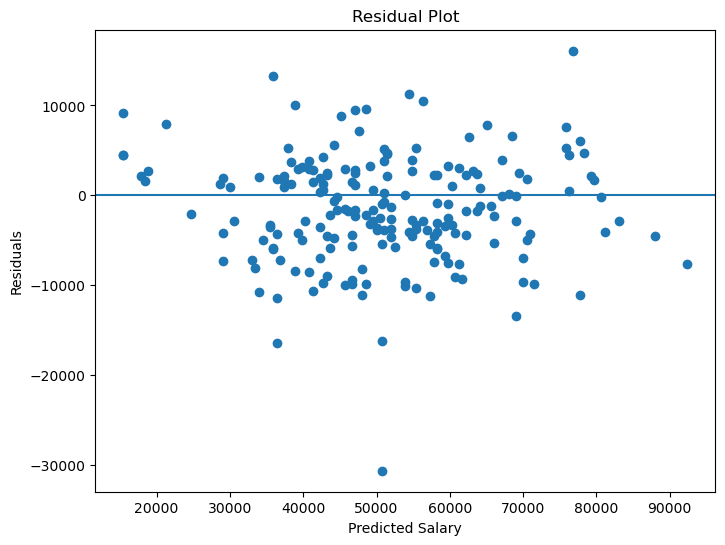

In [42]:
plt.figure(figsize=(8,6))
plt.scatter(test_predictions,residuals)
plt.axhline(y=0)
plt.xlabel('Predicted Salary')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

In [43]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(LinearRegression(),X,y,cv=5, scoring='r2')
print("CV R2 scores:", cv_scores)
print("Mean CV R2:", cv_scores.mean())

CV R2 scores: [0.850581   0.87632182 0.86640837 0.86082483 0.84202197]
Mean CV R2: 0.8592315970920863


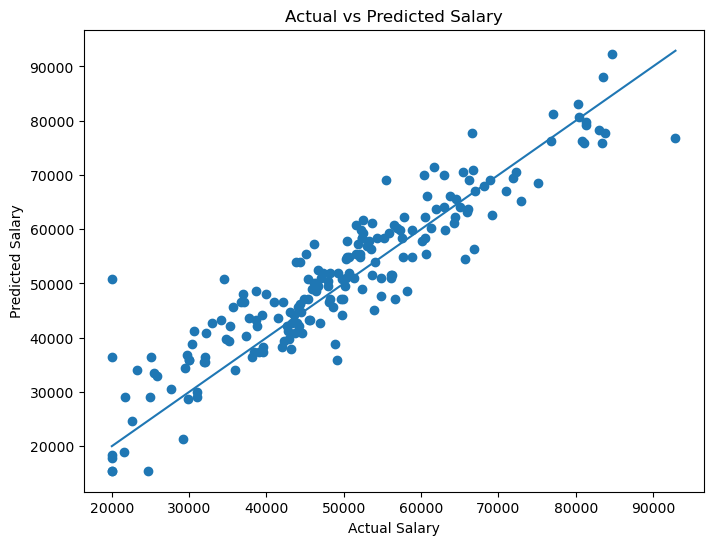

In [47]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,test_predictions)
plt.plot([y_test.min(), y_test.max()],[y_test.min(), y_test.max()])
plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Actual vs Predicted Salary')
plt.show()

In [45]:
experience_values = pd.DataFrame({'Experience_Years': [2, 5, 8, 10]})
predictions = model.predict(experience_values)
prediction_df = pd.DataFrame({
    'Experience_Years': [2, 5, 8, 10],
    'Predicted_Salary': predictions
})
print(prediction_df)

   Experience_Years  Predicted_Salary
0                 2      25208.171225
1                 5      39808.978193
2                 8      54409.785162
3                10      64143.656474


Conclusion:

In this project, a **Simple Linear Regression model** was developed to predict an employee’s salary based on their years of professional experience.

The dataset contained **1,020 employee records** with information such as Age, Gender, Department, Experience_Years, Performance_Score, and Salary. For this project, **Experience_Years was selected as the independent variable (X)** and **Salary was selected as the dependent variable (Y)**.

After performing data cleaning, handling missing values, exploring the data, splitting the dataset into training and testing sets, and training the Linear Regression model, the model achieved a **Training R² score of 0.865** and a **Test R² score of 0.840**.

The model also achieved a **Test Mean Absolute Error (MAE) of approximately ₹4,804**, meaning the average absolute difference between the actual and predicted salary was approximately ₹4,804 on the test data.

Additionally, 5-Fold Cross Validation produced a **mean R² score of approximately 0.859**, indicating that the model provided reasonably consistent performance across different subsets of the data.

Overall, this project demonstrates how **Simple Linear Regression can be used to understand the relationship between professional experience and salary and to estimate salary for new employees based on their years of experience**.
